# Bloque 2: CNN Propia Base en Escala de Grises
En este cuaderno implementamos el modelo baseline de arquitectura propia. Las radiografías se redimensionan a (180, 180) y se procesan en escala de grises.

In [8]:
!pip install numpy
!pip install opencv-python
!pip install scikit-learn
!pip install matplotlib
!pip install tensorflow
!pip install keras-tuner
!pip install kaggle

In [9]:
#@title 1. Montar Drive y cargar datos
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from google.colab import drive
drive.mount('/content/drive')

RUTA_PROYECTO = '/content/drive/MyDrive/Proyecto-neumonia'
os.chdir(RUTA_PROYECTO)
print(f"Directorio de trabajo: {os.getcwd()}")

# Cargar los .npy
X_train = np.load(os.path.join('Subconjunto-datos', 'X_train.npy'))
y_train = np.load(os.path.join('Subconjunto-datos', 'y_train.npy'))
X_val = np.load(os.path.join('Subconjunto-datos', 'X_val.npy'))
y_val = np.load(os.path.join('Subconjunto-datos', 'y_val.npy'))
X_test = np.load(os.path.join('Subconjunto-datos', 'X_test.npy'))
y_test = np.load(os.path.join('Subconjunto-datos', 'y_test.npy'))

print(f"Resumen de dimensiones:")
print(f"  X_train: {X_train.shape} | Rango: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"  X_val:   {X_val.shape}")
print(f"  X_test:  {X_test.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Directorio de trabajo: /content/drive/MyDrive/Proyecto-neumonia
Resumen de dimensiones:
  X_train: (6823, 180, 180, 1) | Rango: [0.00, 1.00]
  X_val:   (1575, 180, 180, 1)
  X_test:  (2100, 180, 180, 1)


In [10]:
#@title 2. Definir la CNN Base
SEED = 230406
tf.keras.utils.set_random_seed(SEED)

BATCH_SIZE = 32
IMG_SHAPE = (180, 180, 1)
EPOCHS = 6

def build_baseline_cnn():
    """Arquitectura CNN base en escala de grises (180, 180, 1)"""
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=IMG_SHAPE),
        MaxPooling2D(2, 2),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D(2, 2),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.AUC(name='auc'),
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall')
        ]
    )
    return model

model_base = build_baseline_cnn()
model_base.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 178, 178, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 118336)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    15,147,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,166,081 (57.85 MB)

 Trainable params: 15,166,081 (57.85 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
#@title 3. Entrenamiento del Modelo Base (Sin Data Augmentation)
print("=" * 70)
print("ENTRENANDO MODELO BASE (SIN DATA AUGMENTATION)")
print("=" * 70)

historial_base = model_base.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    verbose=1
)

# Guardar el modelo
ruta_modelos = os.path.join(RUTA_PROYECTO, 'modelos')
if not os.path.exists(ruta_modelos):
  os.makedirs(ruta_modelos)
ruta_archivo = os.path.join(ruta_modelos, 'modelo_base_sin_da.keras')
model_base.save(ruta_archivo)
print(f"\nModelo guardado en: {ruta_archivo}")

ENTRENANDO MODELO BASE (SIN DATA AUGMENTATION)
Epoch 1/6
214/214 ━━━━━━━━━━━━━━━━━━━━ 463s 2s/step - accuracy: 0.8721 - auc: 0.9447 - loss: 0.3312 - precision: 0.8754 - recall: 0.8675 - val_accuracy: 0.9422 - val_auc: 0.9831 - val_loss: 0.1616 - val_precision: 0.9439 - val_recall: 0.9404
Epoch 2/6
214/214 ━━━━━━━━━━━━━━━━━━━━ 434s 2s/step - accuracy: 0.9478 - auc: 0.9874 - loss: 0.1396 - precision: 0.9491 - recall: 0.9464 - val_accuracy: 0.9562 - val_auc: 0.9877 - val_loss: 0.1328 - val_precision: 0.9568 - val_recall: 0.9556
Epoch 3/6
214/214 ━━━━━━━━━━━━━━━━━━━━ 427s 2s/step - accuracy: 0.9639 - auc: 0.9934 - loss: 0.0997 - precision: 0.9670 - recall: 0.9607 - val_accuracy: 0.9575 - val_auc: 0.9888 - val_loss: 0.1285 - val_precision: 0.9445 - val_recall: 0.9721
Epoch 4/6
214/214 ━━━━━━━━━━━━━━━━━━━━ 468s 2s/step - accuracy: 0.9724 - auc: 0.9957 - loss: 0.0775 - precision: 0.9761 - recall: 0.9686 - val_accuracy: 0.9594 - val_auc: 0.9903 - val_loss: 0.1233 - val_precision: 0.9480 - val_

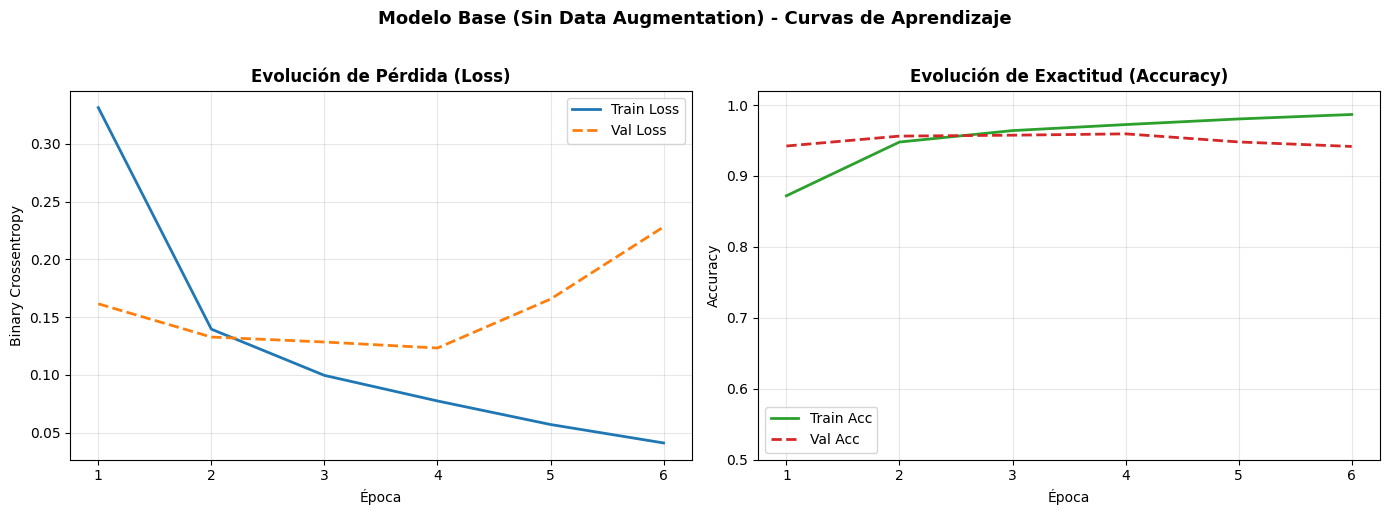

Brecha Overfitting (última época):
  Accuracy: Train 0.9867 | Val 0.9416 | Gap 0.0451
  Loss:     Train 0.0412 | Val 0.2281 | Gap 0.1868


In [12]:
#@title 4. Curvas de Aprendizaje (Pérdida y Exactitud)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
h = historial_base.history
epocas = range(1, len(h['loss']) + 1)

# Pérdida
axes[0].plot(epocas, h['loss'], label='Train Loss', lw=2, color='tab:blue')
axes[0].plot(epocas, h['val_loss'], label='Val Loss', lw=2, linestyle='--', color='tab:orange')
axes[0].set_title("Evolución de Pérdida (Loss)", fontweight='bold')
axes[0].set_ylabel("Binary Crossentropy")
axes[0].set_xlabel("Época")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Exactitud
axes[1].plot(epocas, h['accuracy'], label='Train Acc', lw=2, color='tab:green')
axes[1].plot(epocas, h['val_accuracy'], label='Val Acc', lw=2, linestyle='--', color='tab:red')
axes[1].set_title("Evolución de Exactitud (Accuracy)", fontweight='bold')
axes[1].set_ylabel("Accuracy")
axes[1].set_xlabel("Época")
axes[1].set_ylim(0.5, 1.02)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.suptitle("Modelo Base (Sin Data Augmentation) - Curvas de Aprendizaje",
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Brecha de overfitting
gap_acc = h['accuracy'][-1] - h['val_accuracy'][-1]
gap_loss = h['val_loss'][-1] - h['loss'][-1]
print(f"Brecha Overfitting (última época):")
print(f"  Accuracy: Train {h['accuracy'][-1]:.4f} | Val {h['val_accuracy'][-1]:.4f} | Gap {gap_acc:.4f}")
print(f"  Loss:     Train {h['loss'][-1]:.4f} | Val {h['val_loss'][-1]:.4f} | Gap {gap_loss:.4f}")

In [18]:
#@title 5. Evaluación en X_test - Métricas Clínicas (Priorizando Sensibilidad)
y_prob = model_base.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)  # Sensibilidad clínica
spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

resultados = {
    'Modelo': 'Base (Sin DA)',
    'Accuracy': round(acc, 4),
    'Precision': round(prec, 4),
    'Recall (Sensibilidad)': round(rec, 4),
    'Especificidad': round(spec, 4),
    'F1-Score': round(f1, 4),
    'AUC-ROC': round(auc, 4),
    'Falsos Negativos (FN)': int(fn),
    'Falsos Positivos (FP)': int(fp),
    'Brecha Overfitting (Train-Val Acc)': round(gap_acc, 4)
}

df_resultados = pd.DataFrame([resultados])
display(df_resultados)

print("\nReporte de clasificación detallado:")
print(f"{'':>20} {'precision':>10} {'recall':>10} {'support':>10}")
print(f"{'No Neumonía (0)':>20} {tn/(tn+fn) if (tn+fn)>0 else 0:>10.4f} {tn/(tn+fp) if (tn+fp)>0 else 0:>10.4f}  {tn+fn:>10}")
print(f"{'Neumonía (1)':>20} {tp/(tp+fp) if (tp+fp)>0 else 0:>10.4f} {tp/(tp+fn) if (tp+fn)>0 else 0:>10.4f} {tp+fn:>10}")
print(f"{'accuracy':>20} {'':>10} {'':>10} {tn+fp+fn+tp:>10}")

,Modelo,Accuracy,Precision,Recall (Sensibilidad),Especificidad,F1-Score,AUC-ROC,Falsos Negativos (FN),Falsos Positivos (FP),Brecha Overfitting (Train-Val Acc)
0,Base (Sin DA),0.9462,0.9926,0.899,0.9933,0.9435,0.9938,106,7,0.0451



Reporte de clasificación detallado:
                      precision     recall    support
     No Neumonía (0)     0.9077     0.9933        1149
        Neumonía (1)     0.9926     0.8990       1050
            accuracy                             2100


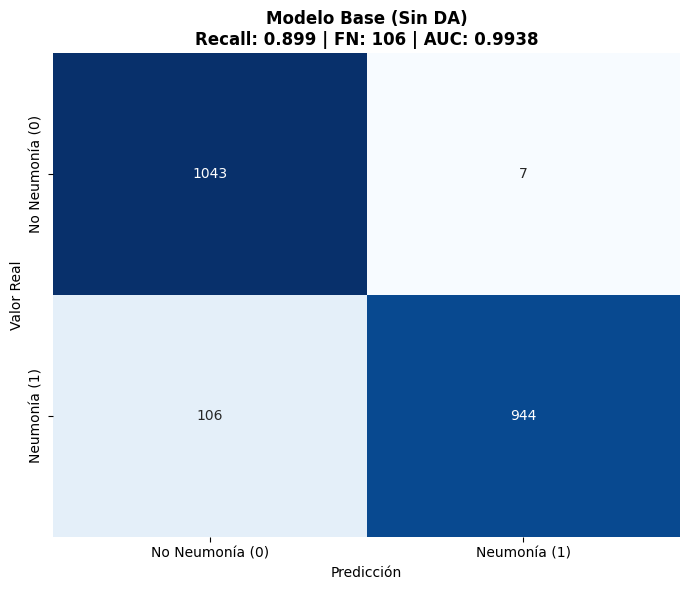

In [14]:
#@title 6. Matriz de Confusión
fig, ax = plt.subplots(1, 1, figsize=(7, 6))

cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['No Neumonía (0)', 'Neumonía (1)'],
            yticklabels=['No Neumonía (0)', 'Neumonía (1)'])
ax.set_title(f"Modelo Base (Sin DA)\nRecall: {rec:.3f} | FN: {fn} | AUC: {auc:.4f}",
             fontweight='bold')
ax.set_xlabel('Predicción')
ax.set_ylabel('Valor Real')
plt.tight_layout()
plt.show()

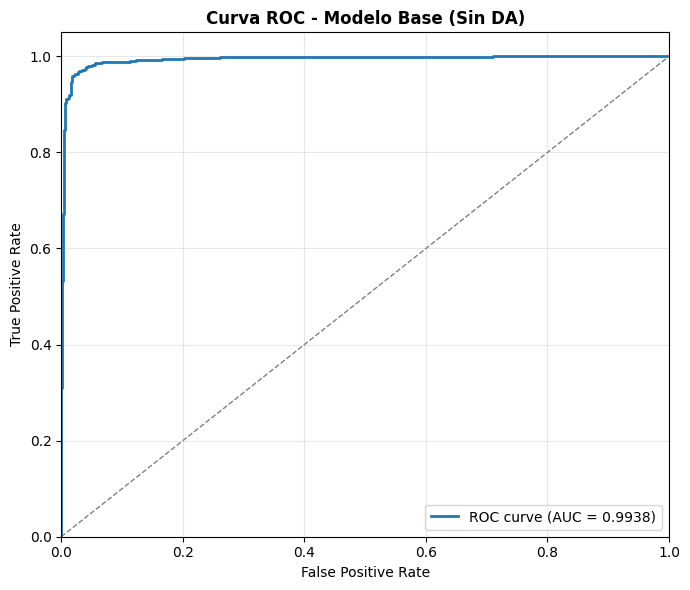

In [15]:
#@title 7. Curva ROC
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

fig, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot(fpr, tpr, color='tab:blue', lw=2, label=f'ROC curve (AUC = {auc:.4f})')
ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Curva ROC - Modelo Base (Sin DA)', fontweight='bold')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
#@title 8. Resumen Final
print("=" * 70)
print("RESUMEN - MODELO BASE (SIN DATA AUGMENTATION)")
print("=" * 70)
print(f"  Accuracy:              {acc:.4f}")
print(f"  Precision:             {prec:.4f}")
print(f"  Recall (Sensibilidad): {rec:.4f}")
print(f"  Especificidad:         {spec:.4f}")
print(f"  AUC-ROC:               {auc:.4f}")
print(f"  Falsos Negativos:      {fn}")
print(f"  Falsos Positivos:      {fp}")
print(f"  Brecha Overfitting:    {gap_acc:.4f}")
print("=" * 70)

RESUMEN - MODELO BASE (SIN DATA AUGMENTATION)
  Accuracy:              0.9462
  Precision:             0.9926
  Recall (Sensibilidad): 0.8990
  Especificidad:         0.9933
  F1-Score:              0.9435
  AUC-ROC:               0.9938
  Falsos Negativos:      106
  Falsos Positivos:      7
  Brecha Overfitting:    0.0451
